In this notebook/script I will obtain different built environment predictors for the temperature. I will focus on the following ones:


<ol>
<li>SVF: Sky View Factor</li>
<li>GVI: Green View Index</li>
<li>Number of cars</li>
<li>Number of people</li>
</ol>

The two last ones are of course experimental. Other maps to obtain from satellite data are:

<ol>
<li>NDVI (which could be compared with GVI)</li>
<li>Street Network density. This one could be defined as:
</li>
</ol>

\begin{equation}
\text{Network density} = \frac{\text{Number of nodes}}{\text{Area}}
\end{equation}

In [ ]:
from pathlib import Path
import sys
import pandas as pd

from src.kriging.utils import get_bounding_box


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError("Could not find project root.")


project_root = find_project_root(Path.cwd())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

parent_path = project_root / "data" / "kriging_street_view"
sensor_locations_path = project_root / "data" / "spatial" / "sensor_locations.json"

sensor_locations = pd.read_json(sensor_locations_path)
print(f"Loaded {len(sensor_locations)} sensor locations")

# Compute bounding box from sensor locations
points = list(zip(sensor_locations["longitude"], sensor_locations["latitude"]))
box = get_bounding_box(points, delta=0.01)

In [2]:
from utils import get_area_grid, get_square_dimensions

grid = get_area_grid(box, n_cells = 30)
width, height = get_square_dimensions(grid[0])
print(f"Each cell is {width} meters wide and {height} meters tall.")

Each cell is 63.518189795548096 meters wide and 50.02700102305971 meters tall.


In [ ]:
# Export bounding box and grid to GeoJSON for use in other notebooks.
from src.kriging.utils import export_bounding_box, export_grid_geojson

crs = "EPSG:4326"
export_bounding_box(box, parent_path / "bounding_box.geojson", crs=crs)
export_grid_geojson(grid, parent_path / "grid_rectangles.geojson", crs=crs)
print("Exported bounding box and grid")

<Axes: >

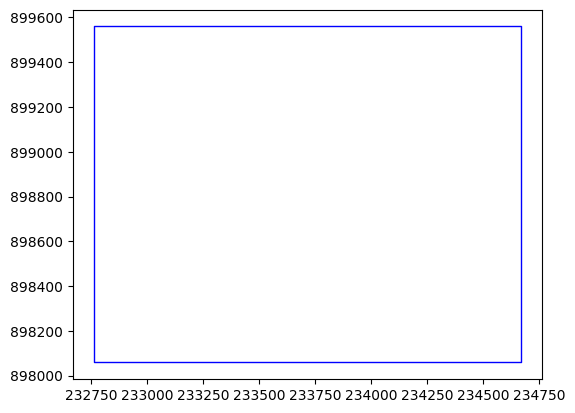

In [4]:
#Testing opening the bounding box geojson file and plotting it. 
import geopandas as gpd

gdf = gpd.read_file(f"{parent_path}/bounding_box.geojson")
gdf.plot(facecolor ="none", edgecolor = "blue")

In [ ]:
# alivestreets: external library for street-view collection.
# Install separately to use this cell: pip install alivestreets
# Uncomment the import below once installed.
#
# sys.path.append("/path/to/alivestreets/src")
# from alivestreets.streetview_collection.streetview_network_collection import StreetViewNetworkCollector
# from alivestreets.sampling.street_sampler import StreetSampler
# from alivestreets.network.network_retrieval import get_graph_from_point, export_graph_geojson

In [6]:
from alivestreets.sampling.street_sampler import StreetSampler
from alivestreets.network.network_retrieval import get_graph_from_point, export_graph_geojson

center_point = gdf.geometry.centroid.iloc[0]
#Transform to lat,lon
transformer = Transformer.from_crs("EPSG:26986", "EPSG:4326", always_xy=True)
center_point = transformer.transform(center_point.x, center_point.y)
square = gdf.geometry.iloc[0]
#radius = 
print(center_point)

(-71.09086604340001, 42.33904737860646)


In [ ]:
import numpy as np
from shapely.geometry import Point, LineString

square = gdf.geometry.iloc[0]
center = square.centroid

corners = list(square.exterior.coords)[:-1]
corner_distances = [center.distance(Point(x, y)) for x, y in corners]
radius_to_corner = max(corner_distances)


side_midpoints = []
coords = corners + [corners[0]]
for i in range(4):
    p1, p2 = coords[i], coords[i + 1]
    side_midpoints.append(LineString([p1, p2]).interpolate(0.5, normalized=True))

midpoint_distances = [center.distance(mp) for mp in side_midpoints]
radius_to_side_midpoint = max(midpoint_distances)  

print("center (projected):", (center.x, center.y))
print("radius corner:", radius_to_corner)
print("radius side midpoint:", radius_to_side_midpoint)

center (projected): (233715.29950326838, 898809.0902738097)
radius corner: 1212.7999772874168
radius side midpoint: 952.7728469330759


Exported: /Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/Shared drives/Drawing Together/Sensor/Sensor Data Analysis/Interpolation Experiments (kriging)/data/network/network.geojson


<Axes: >

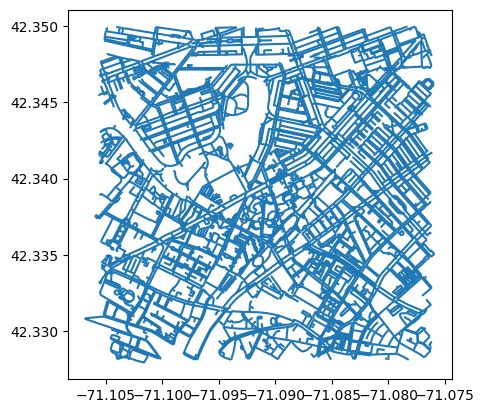

In [8]:
radius = 1213
G = get_graph_from_point(
    lat = center_point[1], lon = center_point[0],
    radius = radius, 
    network_type="walk")

export_graph_geojson(G, parent_path/"network/network.geojson")

gdf_network = gpd.read_file(parent_path/"network/network.geojson")
gdf_network.plot()


6231


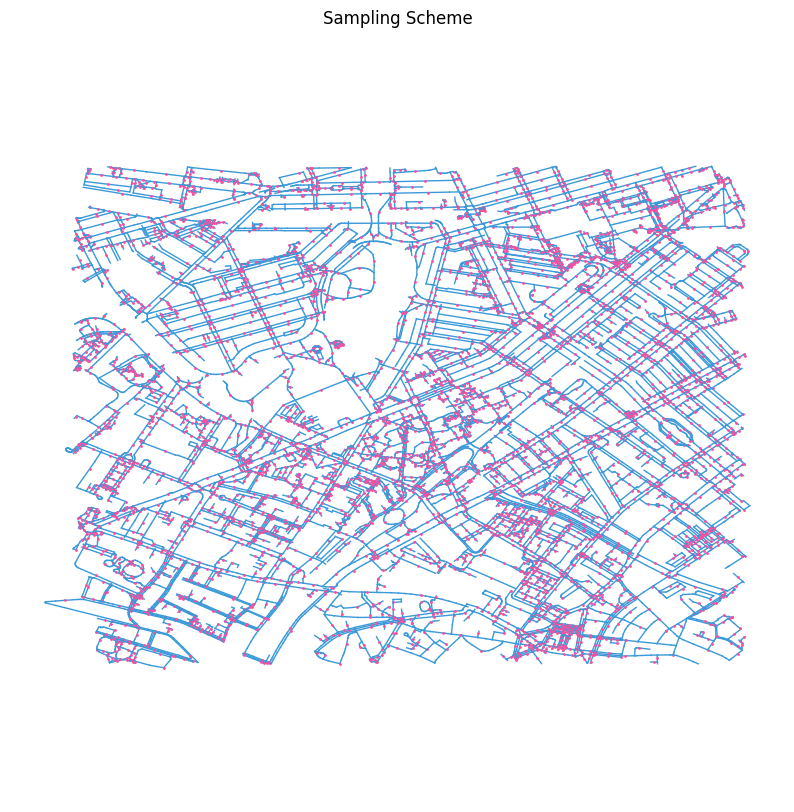

In [9]:
n_sampling_points = 1000
street_sampler = StreetSampler(n_sampling_points)

street_sampler.open_streets(parent_path/"network/network.geojson")
street_sampler.sample_streets_no_intersections()
street_sampler.draw_sampling_scheme()

print(len(street_sampler.get_all_sampling_points()))

In [ ]:
# Collect sidewalk images using the alivestreets library.
# Set GOOGLE_MAPS_API_KEY in your environment before running:
#   export GOOGLE_MAPS_API_KEY="your_key_here"
import os

# from alivestreets.streetview_collection.streetview_network_collection import StreetViewNetworkCollector
# api_key = os.environ["GOOGLE_MAPS_API_KEY"]
# collector = StreetViewNetworkCollector(mode="sidewalks", api_key=api_key)
# collector.collect_street_sampler_images(
#     street_sampler,
#     parent_output_location=parent_path / "streetview_images",
# )

In [12]:
# Load already-collected point dictionaries
point_dictionaries_path = parent_path / "streetview_images" / "point_dictionaries.jsonl"

point_dicts = [json.loads(line) for line in open(point_dictionaries_path)]
print(f"Loaded {len(point_dicts)} point dictionaries")

Model already exists. Loaded existing model.
Vegetation class ID: 12


100%|██████████| 6228/6228 [54:14<00:00,  1.91it/s]


In [15]:
#For some reason there are less points, I'll just add None 
gvi_values.append(None)
gvi_values.append(None)
gvi_values.append(None)
gvi_values.append(None)

In [16]:
street_sampler.get_number_of_sampling_points()

6231

In [21]:
street_sampler.tag_streets(
    "GVI",
    gvi_values
)

In [22]:
from alivestreets.sampling.geojson_sampler_exporter import StreetSamplerGeojsonExporter

exporter = StreetSamplerGeojsonExporter(street_sampler)
export_path = parent_path/"tagged_streets_gvi.geojson"
exporter.export(export_path)



Text(0.5, 1.0, 'GVI')

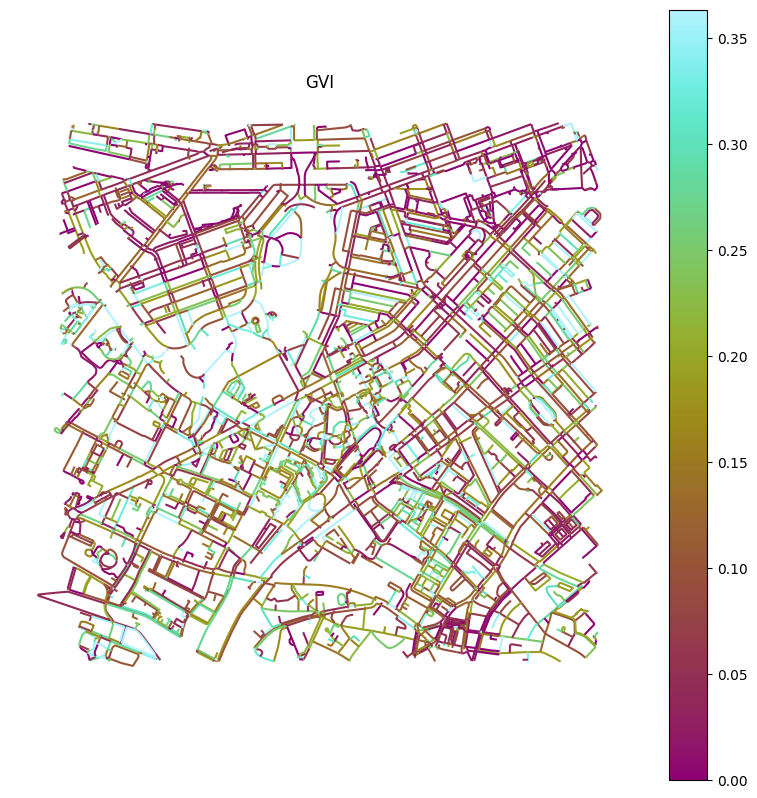

In [ ]:
import geopandas as gpd
import cmcrameri.cm as cmc

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize = (10, 10))
gdf_gvi = gpd.read_file(export_path)
min_percentile = 5
max_percentile = 95
min_value = gdf_gvi["GVI"].quantile(min_percentile/100)
max_value = gdf_gvi["GVI"].quantile(max_percentile/100)
gdf_gvi["clipped"] = gdf_gvi["GVI"].clip(lower=min_value, upper=max_value)
gdf_gvi.plot(column="clipped", legend=True, cmap=cmc.hawaii, ax = ax)
ax.set_axis_off()
ax.set_title("GVI")

In [ ]:
#Let's try to aggregate this over a grid 
grid = gpd.read_file(parent_path/"grid_rectangles.geojson")



In [28]:
import geopandas as gpd
import pandas as pd

# Inputs
gdf_gvi = gpd.read_file(export_path)                      # tagged street network (likely LineString)
grid = gpd.read_file(parent_path / "grid_rectangles.geojson")

# 1) Make sure both layers share CRS
if gdf_gvi.crs != grid.crs:
    gdf_gvi = gdf_gvi.to_crs(grid.crs)



streets = gdf_gvi[["GVI", "geometry"]].copy()
grid_ix = grid.reset_index(names="grid_id")[["grid_id", "geometry"]]

parts = gpd.overlay(streets, grid_ix, how="intersection")

# 3) Length-weighted aggregation per grid cell
parts["seg_len"] = parts.geometry.length
parts["gvi_len"] = parts["GVI"] * parts["seg_len"]

agg = (
    parts.groupby("grid_id")
    .agg(
        gvi_mean_weighted=("gvi_len", lambda s: s.sum() / parts.loc[s.index, "seg_len"].sum()),
        gvi_mean=("GVI", "mean"),
        gvi_median=("GVI", "median"),
        gvi_std=("GVI", "std"),
        n_segments=("GVI", "count"),
        total_len=("seg_len", "sum"),
    )
    .reset_index()
)

# 4) Attach aggregated values back to the grid
grid_agg = grid_ix.merge(agg, on="grid_id", how="left").merge(
    grid.drop(columns="geometry"), left_on="grid_id", right_index=True, how="left"
)
grid_agg = gpd.GeoDataFrame(grid_agg, geometry="geometry", crs=grid.crs)

Text(0.5, 1.0, 'Grid-aggregated GVI (length-weighted)')

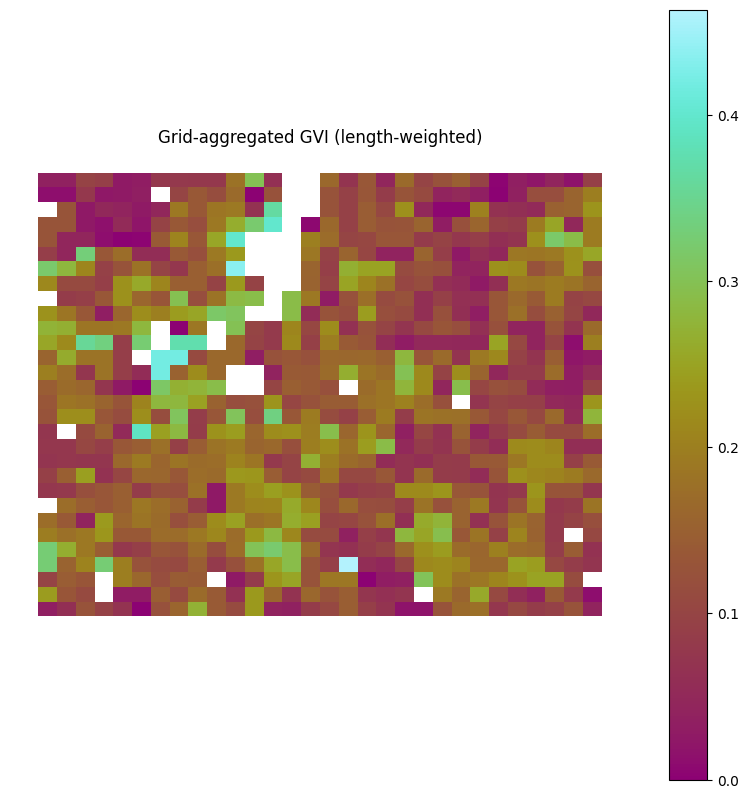

In [33]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
grid_agg.plot(column="gvi_median", cmap=cmc.hawaii, legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Grid-aggregated GVI (length-weighted)")

In [34]:
grid_agg.to_file(parent_path/"grid_aggregated_gvi.geojson", driver="GeoJSON")